# Environment 3: Grid Navigation with Random Mines (Dynamic Reasoning)
### Comparative Evaluation: Training From Scratch (3500 eps) vs. Curriculum Transfer from Env 1+2 (2000 eps)

In **Environment 3**, our agent faces a true generalization test:
- **Sidewalks**: **OFF** .
- **Grid Layout**: $8 \times 6$ grid (8 columns, 6 rows).
- **Mines**: **RANDOMIZED ON EVERY RESET** 
- **Goal Zone**: The entire right column (`col 7`, rows 0–5). **+100 reward on WIN**.
- **The Core AI Challenge**:
  - In Env 1 and Env 2, mine locations were static per seed, enabling route memorization.
  - In Env 3, the minefield is re-rolled dynamically on every single reset.
  - **Static path memorization is impossible.**
  - The agent must rely on its spatial Conv2D features and revealed adjacent numbers ($0, 1, 2...$) to infer safe paths on the fly!

---

### Core Comparative Investigation:
We conduct an empirical two-way comparison:
1. **Condition A (From Scratch)**: Agent trained completely fresh on Env 3 for **`3500 episodes`** with zero prior knowledge.
2. **Condition B (Transferred & Fine-Tuned)**: Agent pre-trained on the Env 1 $\to$ Env 2 curriculum, fine-tuned for **`2000 episodes`**.

We measure:
- **Zero-Shot Generalization**: Can the Env 2 agent navigate dynamic layouts before fine-tuning?
- **Sample Efficiency**: How much faster does curriculum pre-training converge on stochastic boards?
- **Training Wall-Clock Time**: Computational speedup of transfer learning.
- **Schema Generalization**: Value field stability under dynamic hazard relocation.
- **Curriculum Catastrophic Forgetting**: Measuring retention across Env 1, Env 2, and Env 3.



## 1. Setup & Environment Registration


In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))

import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import torch

import environment
from environment.grid_nav_env import (
    GridNavEnv, ACTION_NAMES,
    MOVE_UP, MOVE_DOWN, MOVE_LEFT, MOVE_RIGHT
)
from models.grid_dqn_agent import GridNavDQNAgent, GridStateEncoder, train_dqn_agent
from notebooks.visualizer import (
    record_episode, record_winning_episode, plot_trajectory,
    draw_grid_state, plot_q_value_heatmap, evaluate_agent_retention,
    run_forgetting_benchmark, plot_transfer_comparison
)

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA Available:  {torch.cuda.is_available()}")
print("Environment 3 registered successfully!")



PyTorch version: 2.10.0+cpu
CUDA Available:  False
Environment 3 registered successfully!


## 2. Visualizing Dynamic Mine Relocation Across Resets
Below we run 3 consecutive `reset()` calls on `GridNavMinesweeper-v3`.
Notice how the red mine locations shift to entirely new tiles on each reset!



C:\Users\USER\AppData\Local\Programs\Python\Python312\Lib\site-packages\gymnasium\envs\registration.py:511: DeprecationWarning: WARN: The environment GridNavMinesweeper-v3 is out of date. You should consider upgrading to version `v4`.
  logger.deprecation(


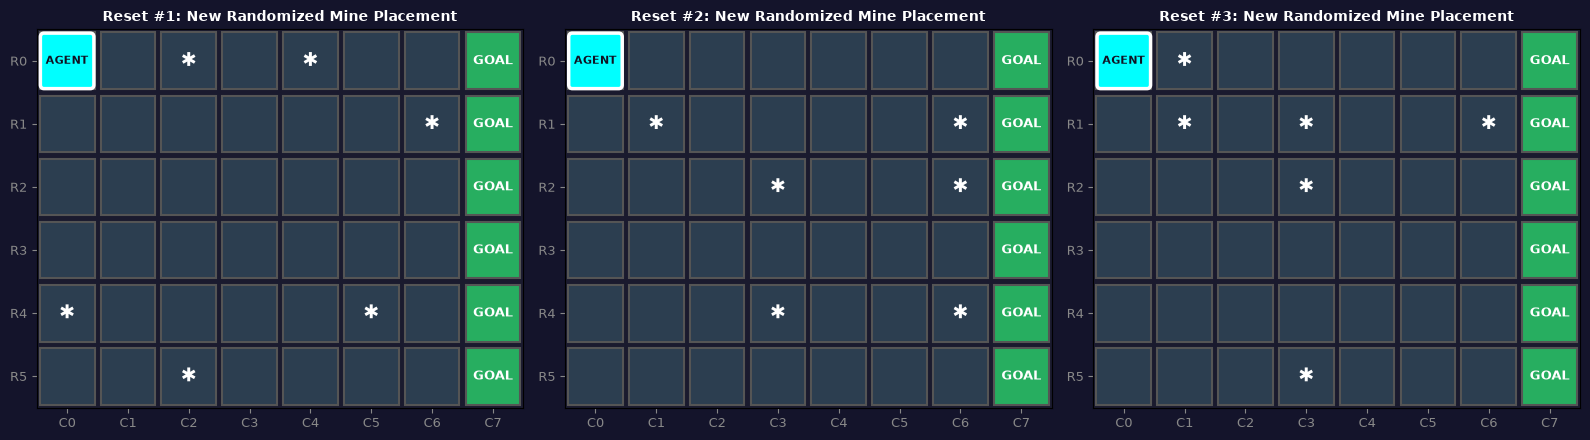

The minefield is randomized on every episode. Path memorization is impossible!


In [2]:
env = gym.make("GridNavMinesweeper-v3")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), facecolor="#14142B")

for i, ax in enumerate(axes):
    obs, info = env.reset()
    frame = {
        "board": obs["board"],
        "cell_types": obs["cell_types"],
        "agent_pos": obs["agent_pos"],
        "action_name": f"RESET #{i+1}",
        "reward": 0.0,
        "event": "start",
        "step": 0,
        "mine_map": env.unwrapped._mine_map,
    }
    draw_grid_state(ax, frame, show_mines=True)
    ax.set_title(f"Reset #{i+1}: New Randomized Mine Placement", color="white", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.show()

print("The minefield is randomized on every episode. Path memorization is impossible!")



## 3. Zero-Shot Evaluation: How Does the Env 2 Agent Behave on Random Boards?

We evaluate the agent trained on Env 2 directly on Env 3 before fine-tuning.



Loaded Env 2 checkpoint from checkpoints/env2_dqn.pt

=== Zero-Shot Performance on Dynamic Board (Seed 101) ===
  Steps Taken:  5
  Won:          False
  Final Event:  mine_hit
  Total Reward: -98.5


C:\Users\USER\AppData\Local\Programs\Python\Python312\Lib\site-packages\gymnasium\envs\registration.py:511: DeprecationWarning: WARN: The environment GridNavMinesweeper-v3 is out of date. You should consider upgrading to version `v4`.
  logger.deprecation(


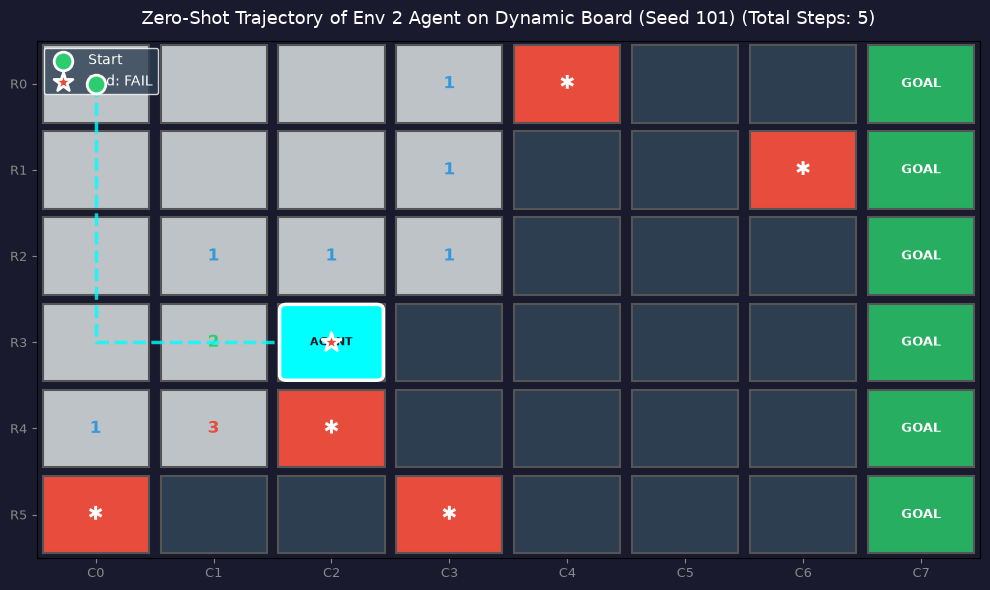

In [3]:
zero_shot_agent = GridNavDQNAgent(
    grid_size=(env.unwrapped.grid_width, env.unwrapped.grid_height),
    num_actions=4,
)

checkpoint_path = "checkpoints/env2_dqn.pt"
if os.path.exists(checkpoint_path):
    zero_shot_agent.load(checkpoint_path, load_buffer=False)
    print(f"Loaded Env 2 checkpoint from {checkpoint_path}")
else:
    print(f"Checkpoint not found at {checkpoint_path} — please run Notebook 2 first!")

eval_env = gym.make("GridNavMinesweeper-v3", seed=101)
zero_shot_history = record_episode(eval_env, zero_shot_agent, evaluate=True, seed=101)

print(f"\n=== Zero-Shot Performance on Dynamic Board (Seed 101) ===")
print(f"  Steps Taken:  {len(zero_shot_history)-1}")
print(f"  Won:          {zero_shot_history[-1].get('won')}")
print(f"  Final Event:  {zero_shot_history[-1].get('event')}")
print(f"  Total Reward: {sum(f['reward'] for f in zero_shot_history):.1f}")

plot_trajectory(zero_shot_history, title="Zero-Shot Trajectory of Env 2 Agent on Dynamic Board (Seed 101)")



## 4. Condition A: Training From Scratch on Env 3 (3500 Episodes)

We train a fresh agent with random initialization on the randomized minefield for **`3500 episodes`**.



In [4]:
NUM_EPISODES_SCRATCH = 3500

scratch_env = gym.make("GridNavMinesweeper-v3")

scratch_agent = GridNavDQNAgent(
    grid_size=(scratch_env.unwrapped.grid_width, scratch_env.unwrapped.grid_height),
    num_actions=4,
    lr=1e-3,
    gamma=0.98,
    epsilon_start=1.0,
    epsilon_min=0.05,
    epsilon_decay=0.985,
    batch_size=64,
    target_update_freq=10,
)

scratch_metrics = train_dqn_agent(
    env=scratch_env,
    agent=scratch_agent,
    num_episodes=NUM_EPISODES_SCRATCH,
    update_freq=4,
    warmup_steps=64,
    verbose_freq=100,
)

os.makedirs("checkpoints", exist_ok=True)
scratch_agent.save("checkpoints/env3_scratch.pt", save_buffer=True)
print(f"\nSaved Scratch model to checkpoints/env3_scratch.pt")



C:\Users\USER\AppData\Local\Programs\Python\Python312\Lib\site-packages\gymnasium\envs\registration.py:511: DeprecationWarning: WARN: The environment GridNavMinesweeper-v3 is out of date. You should consider upgrading to version `v4`.
  logger.deprecation(


Starting DQN Training on GridNavEnv for 3500 episodes...
═══════════════════════════════════════════════════════════════════════════
   Ep |   Reward |  Win% (25) |  Steps |  Epsilon |  Explor% | Time (s)
───────────────────────────────────────────────────────────────────────────


  100 |    -36.1 |      32.0% |      6 |    0.221 |     0.0% |     10.2s


  200 |    -27.3 |      36.0% |      7 |    0.050 |    14.3% |     18.8s


  300 |     +5.1 |      52.0% |      8 |    0.050 |    12.5% |     26.0s


  400 |    -20.3 |      40.0% |      6 |    0.050 |     0.0% |     32.8s


... (28 outputs left out)

 3300 |    -23.3 |      40.0% |      6 |    0.050 |     0.0% |    245.1s


 3400 |    -68.2 |      16.0% |      7 |    0.050 |     0.0% |    251.1s


 3500 |    -51.5 |      28.0% |      7 |    0.050 |     0.0% |    258.1s
═══════════════════════════════════════════════════════════════════════════
Training completed in 258.12s!
First Goal reached at Episode 30!
Final 25-episode win rate: 28.0%



Saved Scratch model to checkpoints/env3_scratch.pt


## 5. Condition B: Curriculum Transfer from Env 1+2 & Fine-Tune (2000 Episodes)

We load the weights pre-trained on Env 1 and Env 2, clear the replay buffer for clean adaptation, and fine-tune for **`2000 episodes`**.



In [5]:
NUM_EPISODES_TRANSFER = 2000

transfer_env = gym.make("GridNavMinesweeper-v3")

transferred_agent = GridNavDQNAgent(
    grid_size=(transfer_env.unwrapped.grid_width, transfer_env.unwrapped.grid_height),
    num_actions=4,
    lr=1e-3,
    gamma=0.98,
    epsilon_start=1.0,
    epsilon_min=0.05,
    epsilon_decay=0.985,
    batch_size=64,
    target_update_freq=10,
)

if os.path.exists("checkpoints/env2_dqn.pt"):
    transferred_agent.load("checkpoints/env2_dqn.pt", load_buffer=False)
    transferred_agent.clear_buffer()
    transferred_agent.epsilon = 1.0
    print("Successfully loaded Env 2 curriculum weights!")
else:
    print("Env 2 checkpoint not found — starting fresh.")

transfer_metrics = train_dqn_agent(
    env=transfer_env,
    agent=transferred_agent,
    num_episodes=NUM_EPISODES_TRANSFER,
    update_freq=4,
    warmup_steps=64,
    verbose_freq=100,
)

transferred_agent.save("checkpoints/env3_transferred.pt", save_buffer=True)
transferred_agent.save("checkpoints/env3_dqn.pt", save_buffer=True)
print(f"\nSaved Transferred model to checkpoints/env3_transferred.pt and checkpoints/env3_dqn.pt")



Successfully loaded Env 2 curriculum weights!
Starting DQN Training on GridNavEnv for 2000 episodes...
═══════════════════════════════════════════════════════════════════════════
   Ep |   Reward |  Win% (25) |  Steps |  Epsilon |  Explor% | Time (s)
───────────────────────────────────────────────────────────────────────────


  100 |    -12.1 |      44.0% |      4 |    0.221 |    25.0% |      7.1s


  200 |    -35.4 |      32.0% |      7 |    0.050 |     0.0% |     11.4s


  300 |    -51.0 |      24.0% |      3 |    0.050 |     0.0% |     15.8s


  400 |     +5.2 |      52.0% |      3 |    0.050 |     0.0% |     20.2s


  500 |    -10.7 |      44.0% |      6 |    0.050 |    16.7% |     24.5s


... (12 outputs left out)

 1800 |     -3.1 |      48.0% |      7 |    0.050 |     0.0% |     87.7s


 1900 |    -34.8 |      32.0% |      3 |    0.050 |     0.0% |     92.5s


 2000 |    -35.2 |      32.0% |      6 |    0.050 |     0.0% |     97.0s
═══════════════════════════════════════════════════════════════════════════
Training completed in 96.96s!
First Goal reached at Episode 42!
Final 25-episode win rate: 32.0%



Saved Transferred model to checkpoints/env3_transferred.pt and checkpoints/env3_dqn.pt


## 6. Comparative Results: From Scratch (3500 eps) vs. Transferred (2000 eps)
We compare success rates, learning speed, steps taken, and training duration.



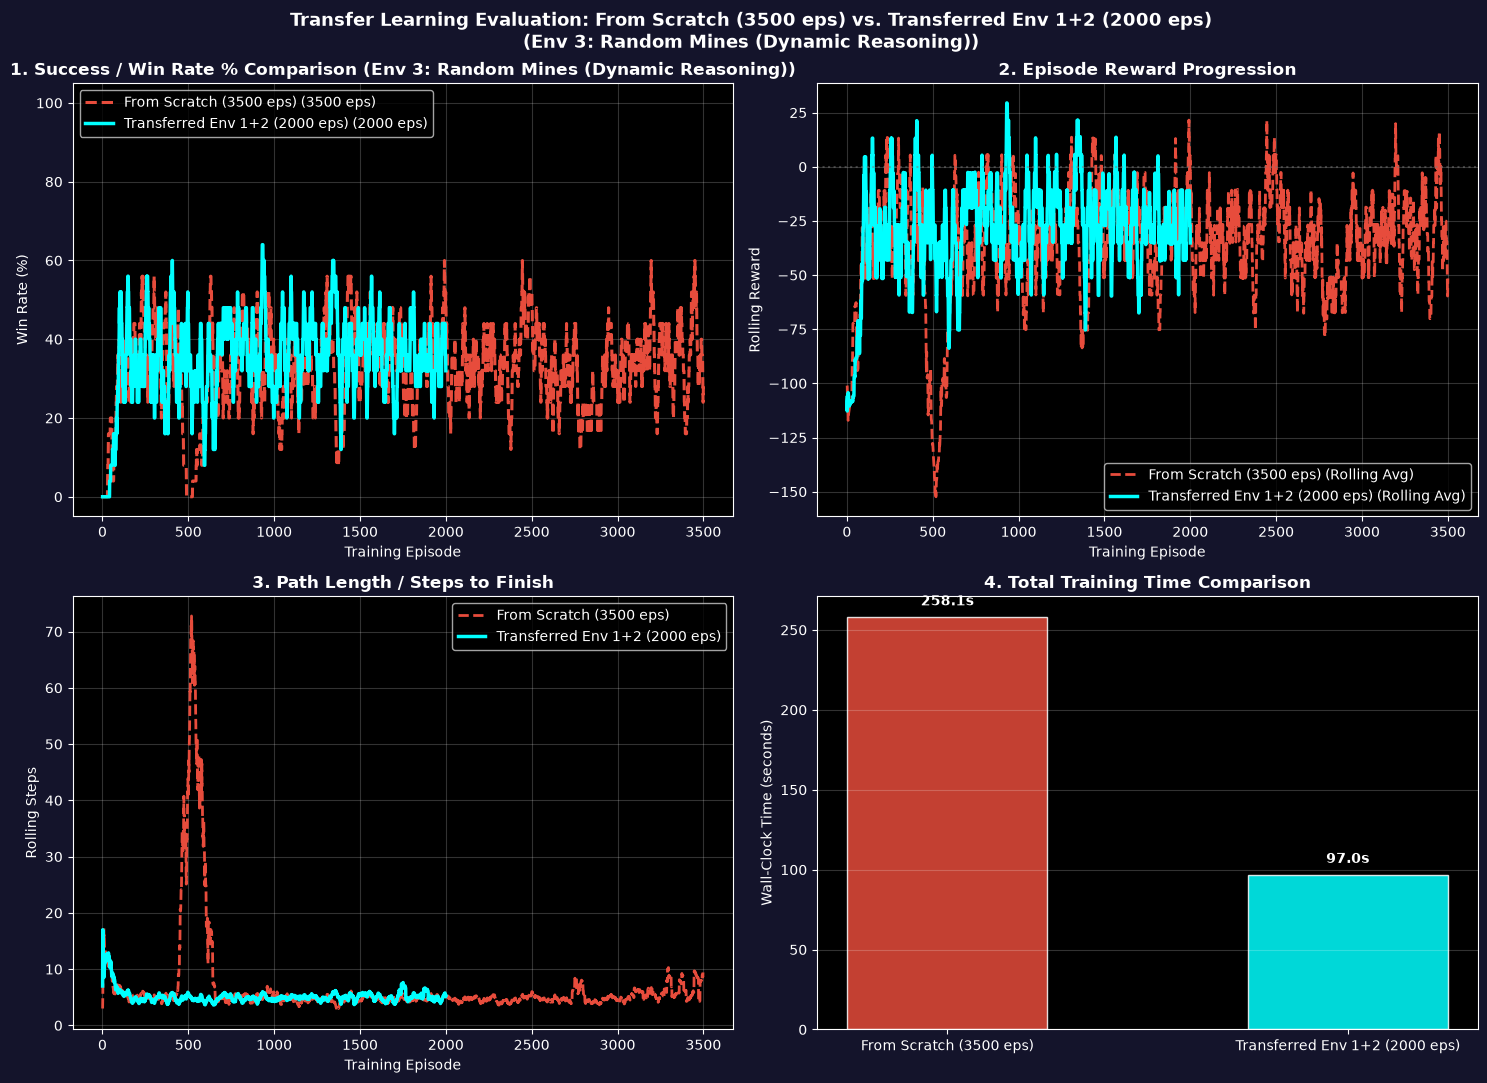


=== Summary Comparison Table ===
Condition                        |  Episodes | Final Win Rate | Total Time
------------------------------------------------------------------------
Condition A: From Scratch        |      3500 |          28.0% |     258.1s
Condition B: Transferred Env 1+2 |      2000 |          32.0% |      97.0s


In [6]:
plot_transfer_comparison(
    scratch_metrics=scratch_metrics,
    transfer_metrics=transfer_metrics,
    env_name="Env 3: Random Mines (Dynamic Reasoning)",
    scratch_label=f"From Scratch ({NUM_EPISODES_SCRATCH} eps)",
    transfer_label=f"Transferred Env 1+2 ({NUM_EPISODES_TRANSFER} eps)",
)

print("\n=== Summary Comparison Table ===")
print(f"{'Condition':32s} | {'Episodes':>9} | {'Final Win Rate':>14} | {'Total Time':>10}")
print("-" * 72)
print(f"{'Condition A: From Scratch':32s} | {NUM_EPISODES_SCRATCH:>9d} | {scratch_metrics['rolling_win_rate'][-1]:>13.1f}% | {scratch_metrics['cumulative_time'][-1]:>9.1f}s")
print(f"{'Condition B: Transferred Env 1+2':32s} | {NUM_EPISODES_TRANSFER:>9d} | {transfer_metrics['rolling_win_rate'][-1]:>13.1f}% | {transfer_metrics['cumulative_time'][-1]:>9.1f}s")



## 7. Trajectory Analysis on a Dynamic Board
We inspect the path taken by the fine-tuned agent on a freshly randomized layout.



Replaying best winning trajectory (Ep 42) | Steps: 7 | Won: True


C:\Users\USER\AppData\Local\Programs\Python\Python312\Lib\site-packages\gymnasium\envs\registration.py:511: DeprecationWarning: WARN: The environment GridNavMinesweeper-v3 is out of date. You should consider upgrading to version `v4`.
  logger.deprecation(


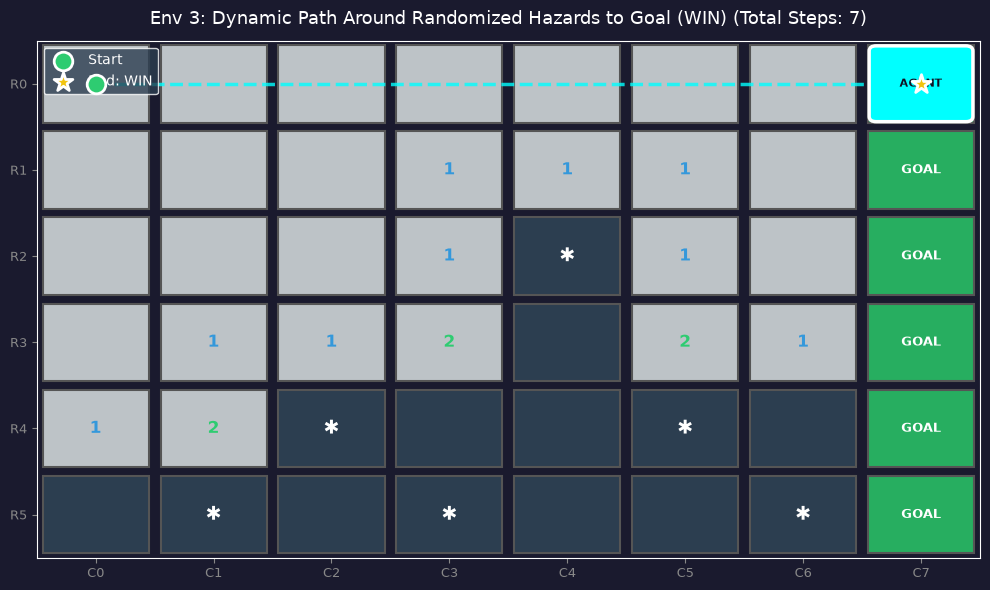

In [7]:
eval_env_test = gym.make("GridNavMinesweeper-v3", seed=101)

if transfer_metrics.get("best_winning_history") is not None:
    history_win = transfer_metrics["best_winning_history"]
    print(f"Replaying best winning trajectory (Ep {transfer_metrics['first_win_episode']}) | Steps: {len(history_win)-1} | Won: {history_win[-1].get('won')}")
else:
    history_win = record_episode(
        eval_env_test,
        actions_script=[MOVE_DOWN] * 2 + [MOVE_RIGHT] * 7,
        start_pos=(0, 0),
        seed=101
    )

plot_trajectory(history_win, title="Env 3: Dynamic Path Around Randomized Hazards to Goal (WIN)")



## 8. Schema Generalization Under Dynamic Mines: State-Value Heatmap $V(s)$
We inspect the State-Value field $V(s) = \max_a Q(s, a)$ across the board under randomized mine distributions.



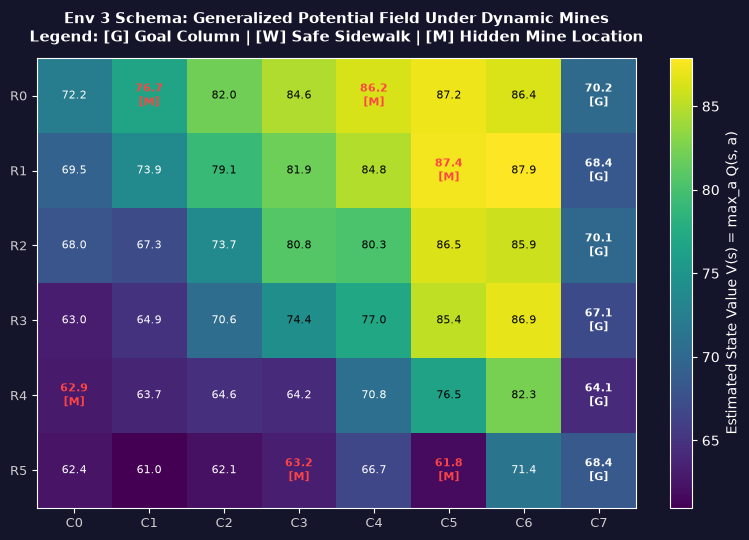

In [8]:
plot_q_value_heatmap(
    agent=transferred_agent,
    env=eval_env_test,
    title="Env 3 Schema: Generalized Potential Field Under Dynamic Mines"
)



## 9. Curriculum Retention: Testing the Env 3 Agent Across All Previous Envs

We test the agent across all three curriculum stages:
1. **Env 1**: Sidewalks ON, fixed mines.
2. **Env 2**: Sidewalks OFF, fixed mines.
3. **Env 3**: Sidewalks OFF, randomized mines.



C:\Users\USER\AppData\Local\Programs\Python\Python312\Lib\site-packages\gymnasium\envs\registration.py:511: DeprecationWarning: WARN: The environment GridNavMinesweeper-v1 is out of date. You should consider upgrading to version `v4`.
  logger.deprecation(
C:\Users\USER\AppData\Local\Programs\Python\Python312\Lib\site-packages\gymnasium\envs\registration.py:511: DeprecationWarning: WARN: The environment GridNavMinesweeper-v2 is out of date. You should consider upgrading to version `v4`.
  logger.deprecation(
C:\Users\USER\AppData\Local\Programs\Python\Python312\Lib\site-packages\gymnasium\envs\registration.py:511: DeprecationWarning: WARN: The environment GridNavMinesweeper-v3 is out of date. You should consider upgrading to version `v4`.
  logger.deprecation(


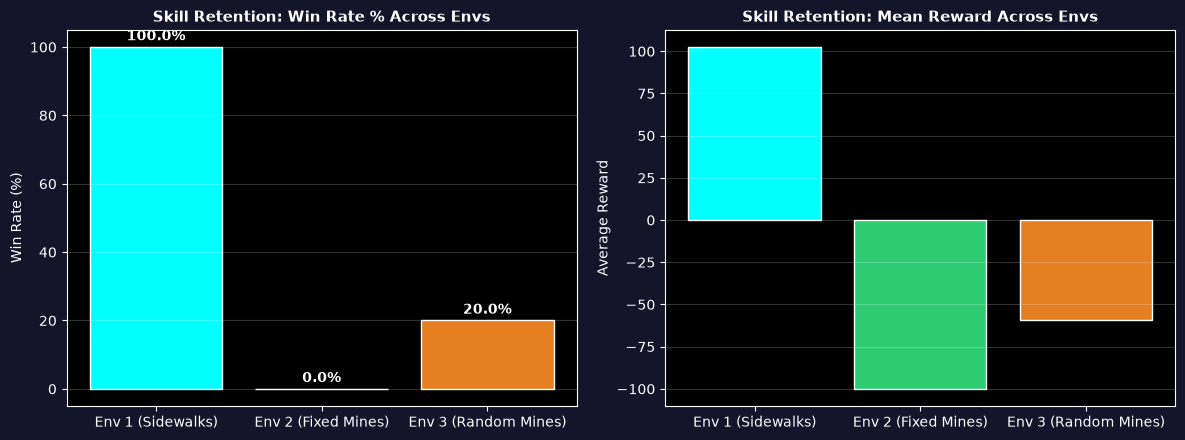


=== Curriculum Retention Benchmark ===
Env 1 (Sidewalks)         | Win Rate: 100.0% | Mean Reward: +102.5
Env 2 (Fixed Mines)       | Win Rate:   0.0% | Mean Reward: -100.0
Env 3 (Random Mines)      | Win Rate:  20.0% | Mean Reward:  -59.1


In [9]:
env1_eval = gym.make("GridNavMinesweeper-v1", seed=42)
env2_eval = gym.make("GridNavMinesweeper-v2", seed=42)
env3_eval = gym.make("GridNavMinesweeper-v3")

full_retention = evaluate_agent_retention(
    agent=transferred_agent,
    env_dict={
        "Env 1 (Sidewalks)": env1_eval,
        "Env 2 (Fixed Mines)": env2_eval,
        "Env 3 (Random Mines)": env3_eval,
    },
    episodes_per_env=25
)

print("\n=== Curriculum Retention Benchmark ===")
for name, res in full_retention.items():
    print(f"{name:25s} | Win Rate: {res['win_rate']:5.1f}% | Mean Reward: {res['avg_reward']:+6.1f}")

